# O "pobre de direita" no segundo turno

O notebook `primeiro-turno/analise_pobre_de_direita.ipynb` mostrou que, no primeiro turno, o quintil de renda mais pobre continua sendo o mais lulista, mas que boa parte disso é Nordeste, e que a direita é forte entre os pobres fora do Nordeste. O segundo turno deixa a pergunta mais limpa: só há dois candidatos, Lula e alguém do PL, em 2022 e em 2026.

Perguntas:

1. O gradiente renda × voto no confronto direto mudou de 2022 para 2026?
2. Lula venceu 2026 avançando em quais faixas de renda e em quais regiões?
3. De onde vêm os votos de cada lado?
4. Dentro do mesmo estado, o que separa os municípios: renda, cor/raça, religião ou instrução?
5. Entre os municípios mais pobres, onde estão os que votaram em Flávio?

**Dados:** presidente por município, 1º e 2º turno de 2022 e 2026 (TSE) e perfil municipal do Censo 2022 (IBGE). Rode `src/download_tse.py` e `src/prepare_segundo_turno.py` antes.

**Leitura obrigatória:** a unidade é o município. "Municípios pobres votaram em Flávio" não é "pobres votaram em Flávio". E renda média municipal mede o lugar, não a pessoa.

In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import statsmodels.formula.api as smf

DATA = Path("../data/processed")
pd.options.display.float_format = "{:,.1f}".format

LULA, FLAVIO, CINZA, TINTA = "#2a78d6", "#eb6834", "#8a8984", "#0b0b0b"
plt.rcParams.update({
    "figure.dpi": 110, "figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False, "axes.spines.right": False, "axes.edgecolor": "#c9c8c2",
    "axes.grid": True, "grid.color": "#e8e7e2", "grid.linewidth": 0.8, "axes.axisbelow": True,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
    "font.size": 10, "text.color": "#0b0b0b", "axes.labelcolor": "#52514e",
    "xtick.color": "#52514e", "ytick.color": "#52514e", "legend.frameon": False,
})
REGIAO = {
    **dict.fromkeys("AC AP AM PA RO RR TO".split(), "Norte"),
    **dict.fromkeys("AL BA CE MA PB PE PI RN SE".split(), "Nordeste"),
    **dict.fromkeys("DF GO MT MS".split(), "Centro-Oeste"),
    **dict.fromkeys("ES MG RJ SP".split(), "Sudeste"),
    **dict.fromkeys("PR RS SC".split(), "Sul"),
}
REG = ["Norte", "Nordeste", "Centro-Oeste", "Sudeste", "Sul"]
# sequencial de um tom só para os quintis (claro = mais pobre)
QCOR = ["#cde2f8", "#9ec5f4", "#5e9ee6", "#2a78d6", "#1a4f93"]

r26 = pd.read_csv(DATA / "presidente_municipio_2026.csv")
r22 = pd.read_csv(DATA / "presidente_municipio_2022.csv")
ib = pd.read_csv(DATA / "ibge_municipio_2022.csv")

## 1. Dados e quintis

Uma linha por município × eleição (ano e turno), sem o exterior. "Lula %" é a fatia de Lula no **confronto direto** Lula + PL, para que o primeiro turno seja comparável ao segundo.

Quintis de **renda média municipal** (rendimento nominal médio das pessoas de 14 anos ou mais, Censo 2022), ponderados pelos votos válidos do 2º turno de 2022: cada quintil tem ~20% dos eleitores. Os quintis são fixados em 2022 para todas as eleições.

In [2]:
chave = r26[r26.turno == 1][["cd_tse", "cd_ibge", "uf", "municipio"]]
partes = []
for ano, d in ((2022, r22), (2026, r26)):
    for t in (1, 2):
        x = d[d.turno == t]
        partes.append(pd.DataFrame({"ano": ano, "turno": t, "cd_tse": x.cd_tse, "lula": x.c13,
                                    "dir": x.c22, "validos": x.validos}))
v = pd.concat(partes).merge(chave, on="cd_tse").merge(ib, on="cd_ibge")
v = v[v.uf != "ZZ"].copy()
v["regiao"] = v.uf.map(REGIAO)
v["lula_pct"] = 100 * v.lula / (v.lula + v.dir)
v["dir_pct"] = 100 - v.lula_pct
v["eleicao"] = v.ano.astype(str) + " " + v.turno.astype(str) + "º t"

ref = v[(v.ano == 2022) & (v.turno == 2)].sort_values("renda")
ref["q"] = np.ceil(5 * ref.validos.cumsum() / ref.validos.sum()).clip(1, 5).astype(int)
v = v.merge(ref[["cd_tse", "q"]], on="cd_tse")
lula = lambda g: 100 * g.lula.sum() / (g.lula.sum() + g.dir.sum())

faixa = ref.groupby("q").renda.agg(["min", "max"]).round(0)
faixa["municípios"] = ref.groupby("q").size()
faixa["Lula % 2º t 2022"] = ref.groupby("q").apply(lula)
print(f"{v.cd_tse.nunique():,} municípios")
display(faixa.rename(columns={"min": "renda mín. (R$)", "max": "renda máx. (R$)"}))

5,570 municípios


,renda mín. (R$),renda máx. (R$),municípios,Lula % 2º t 2022
q,,,,
1,471.0,"1,184.0",2172,72.5
2,"1,184.0","1,703.0",1559,51.0
3,"1,704.0","2,078.0",1057,44.3
4,"2,079.0","2,771.0",644,41.4
5,"2,775.0","5,178.0",138,45.2


## 2. O gradiente no confronto direto

Fatia de Lula por quintil, nas quatro eleições.

q,1,2,3,4,5,Q1 − Q5
eleicao,,,,,,
2022 1º t,74.2,53.0,46.1,43.0,46.5,27.6
2022 2º t,72.5,51.0,44.3,41.4,45.2,27.3
2026 1º t,69.3,48.6,41.4,38.7,44.2,25.1
2026 2º t,71.1,51.7,44.9,42.4,47.5,23.6


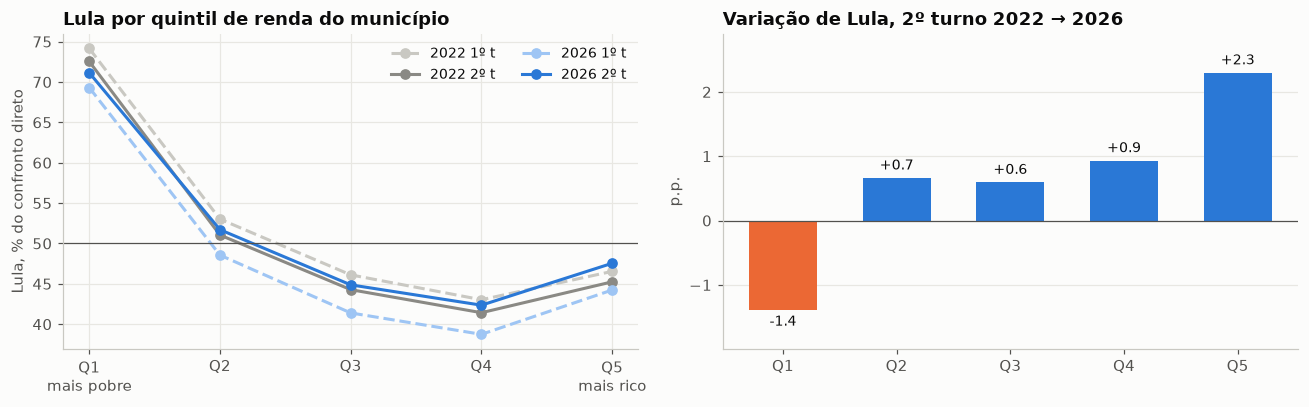

In [3]:
g = v.groupby(["eleicao", "q"]).apply(lula).unstack("q")
g["Q1 − Q5"] = g[1] - g[5]
display(g)

d = g.loc["2026 2º t", [1, 2, 3, 4, 5]] - g.loc["2022 2º t", [1, 2, 3, 4, 5]]
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
estilo = {"2022 1º t": ("#c9c8c2", "--"), "2022 2º t": ("#8a8984", "-"),
          "2026 1º t": ("#9ec5f4", "--"), "2026 2º t": (LULA, "-")}
for k, (c, ls) in estilo.items():
    ax[0].plot(range(1, 6), g.loc[k, [1, 2, 3, 4, 5]], marker="o", color=c, ls=ls, lw=2, label=k)
ax[0].axhline(50, color="#52514e", lw=0.8)
ax[0].set_xticks(range(1, 6), ["Q1\nmais pobre", "Q2", "Q3", "Q4", "Q5\nmais rico"])
ax[0].set_ylabel("Lula, % do confronto direto"); ax[0].set_title("Lula por quintil de renda do município")
ax[0].legend(ncol=2, fontsize=9)
b = ax[1].bar(range(1, 6), d.values, color=[FLAVIO if x < 0 else LULA for x in d.values], width=0.6)
for r, x in zip(b, d.values):
    ax[1].text(r.get_x() + r.get_width() / 2, x + (0.08 if x > 0 else -0.08), f"{x:+.1f}",
               ha="center", va="bottom" if x > 0 else "top", fontsize=9)
ax[1].axhline(0, color="#52514e", lw=0.8); ax[1].grid(axis="x", visible=False)
ax[1].set_xticks(range(1, 6), ["Q1", "Q2", "Q3", "Q4", "Q5"]); ax[1].set_ylabel("p.p.")
ax[1].set_ylim(min(d.min(), 0) - 0.6, d.max() + 0.6)
ax[1].set_title("Variação de Lula, 2º turno 2022 → 2026")
plt.tight_layout(); plt.show()

**Leitura.** O gradiente ficou mais plano. No segundo turno de 2022, Lula tinha 27 p.p. a mais no quintil mais pobre do que no mais rico; em 2026, 24. Lula venceu em 2026 **perdendo** 1,4 p.p. nos municípios mais pobres e ganhando em todos os outros quintis, mais no Q5 (+2,3).

O formato em U também vale notar: o quintil mais rico é mais lulista que os quintis 3 e 4. O Q5 tem só 138 municípios, quase todos capitais e grandes cidades, onde Lula vai melhor do que nas cidades médias de renda intermediária.

## 3. Por região

A mesma variação (2º turno 2022 → 2026, p.p. de Lula no confronto direto) dentro de cada região. Células com menos de 300 mil votos válidos ficam em branco.

Lula % no 2º turno de 2026


q,1,2,3,4,5
regiao,,,,,
Norte,61.5,43.9,42.1,NaN,NaN
Nordeste,74.0,64.1,59.8,63.7,NaN
Centro-Oeste,NaN,44.5,39.7,33.9,41.9
Sudeste,59.3,47.8,44.0,41.9,51.4
Sul,NaN,44.9,40.5,33.5,38.5


Variação 2022 → 2026 (p.p.)


q,1,2,3,4,5
regiao,,,,,
Norte,-1.1,1.3,2.9,NaN,NaN
Nordeste,-1.5,0.8,2.2,3.2,NaN
Centro-Oeste,NaN,-1.2,-1.7,-1.0,3.1
Sudeste,-1.2,0.8,0.9,1.6,2.6
Sul,NaN,-3.5,-1.7,-0.7,1.0


Votos válidos no 2º turno de 2026 (milhões)


q,1,2,3,4,5
regiao,,,,,
Norte,3.8,3.5,2.6,NaN,0.2
Nordeste,20.3,7.4,3.2,4.3,0.1
Centro-Oeste,0.1,1.6,2.3,2.3,3.1
Sudeste,1.7,10.9,11.9,10.2,16.1
Sul,0.0,1.4,4.4,7.6,4.7


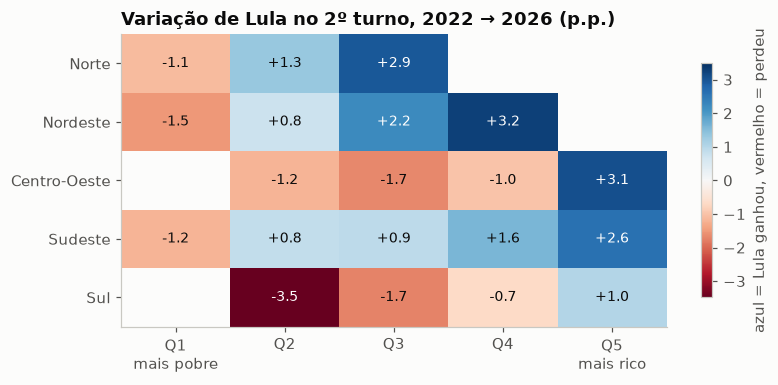

In [4]:
t2 = v[v.turno == 2]
cel = t2.groupby(["regiao", "q", "ano"]).apply(lambda x: pd.Series({"lula": lula(x), "mi": x.validos.sum() / 1e6}))
cel = cel.unstack("ano")
delta = (cel[("lula", 2026)] - cel[("lula", 2022)]).where(cel[("mi", 2026)] >= 0.3).unstack("q").loc[REG]
nivel = cel[("lula", 2026)].where(cel[("mi", 2026)] >= 0.3).unstack("q").loc[REG]
print("Lula % no 2º turno de 2026"); display(nivel)
print("Variação 2022 → 2026 (p.p.)"); display(delta)
print("Votos válidos no 2º turno de 2026 (milhões)"); display(cel[("mi", 2026)].unstack("q").loc[REG])

fig, ax = plt.subplots(figsize=(7.5, 3.6))
lim = np.nanmax(np.abs(delta.values))
im = ax.imshow(delta.values, cmap="RdBu", vmin=-lim, vmax=lim, aspect="auto")
for i in range(delta.shape[0]):
    for j in range(delta.shape[1]):
        val = delta.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f"{val:+.1f}", ha="center", va="center", fontsize=9,
                    color="white" if abs(val) > 0.6 * lim else TINTA)
ax.set_xticks(range(5), ["Q1\nmais pobre", "Q2", "Q3", "Q4", "Q5\nmais rico"]); ax.set_yticks(range(5), REG)
ax.grid(False); ax.set_title("Variação de Lula no 2º turno, 2022 → 2026 (p.p.)")
cb = plt.colorbar(im, ax=ax, shrink=0.8); cb.set_label("azul = Lula ganhou, vermelho = perdeu")
plt.tight_layout(); plt.show()

**Leitura.** Não é efeito de composição regional. Dentro do Norte, do Nordeste e do Sudeste, o quintil mais pobre recua (−1,1 a −1,5 p.p.) e os quintis de cima avançam. No Nordeste, Lula ganhou 3,2 p.p. no Q4 (as cidades maiores da região) e perdeu 1,5 no Q1, onde estão 20 milhões de votos.

Sul e Centro-Oeste são a exceção: lá Lula perdeu terreno nos quintis intermediários, com o maior recuo no Q2 do Sul (−3,5), e só avançou no quintil mais rico.

## 4. De onde vêm os votos de cada lado

A pergunta "o pobre vota na direita?" muda quando se olha de onde vêm os votos, e não quanto cada lugar dá. E, para a vitória de 2026, onde Lula somou os votos que faltavam.

In [5]:
comp = pd.DataFrame({
    "eleitores (válidos 2º t 2026)": t2[t2.ano == 2026].groupby("q").validos.sum(),
    "votos de Lula": t2[t2.ano == 2026].groupby("q").lula.sum(),
    "votos de Flávio": t2[t2.ano == 2026].groupby("q").dir.sum(),
})
display((100 * comp / comp.sum()).rename(columns=lambda c: c + " %"))

var = pd.DataFrame({k: t2[t2.ano == 2026].groupby("q")[c].sum() - t2[t2.ano == 2022].groupby("q")[c].sum()
                    for k, c in (("Lula", "lula"), ("PL", "dir"))})
var["margem"] = var.Lula - var.PL
display((var / 1e6).style.format("{:+.2f} mi"))
print(f"margem de Lula, 2º turno (sem exterior): 2022 {(t2[t2.ano == 2022].lula - t2[t2.ano == 2022].dir).sum():,.0f}"
      f" → 2026 {(t2[t2.ano == 2026].lula - t2[t2.ano == 2026].dir).sum():,.0f}")
print(f"quintis 1+2 respondem por {var.margem[[1, 2]].sum() / var.margem.sum():.0%} do ganho de margem; "
      f"quintis 4+5 por {var.margem[[4, 5]].sum() / var.margem.sum():.0%}")

,eleitores (válidos 2º t 2026) %,votos de Lula %,votos de Flávio %
q,,,
1,21.0,28.8,12.5
2,20.1,20.1,20.1
3,19.6,17.0,22.5
4,19.7,16.1,23.6
5,19.6,18.0,21.3


,Lula,PL,margem
q,,,
1,+1.31 mi,+0.99 mi,+0.32 mi
2,+0.76 mi,+0.41 mi,+0.35 mi
3,+0.49 mi,+0.30 mi,+0.20 mi
4,+0.53 mi,+0.20 mi,+0.33 mi
5,+0.76 mi,-0.31 mi,+1.07 mi


margem de Lula, 2º turno (sem exterior): 2022 2,132,004 → 2026 4,402,942
quintis 1+2 respondem por 30% do ganho de margem; quintis 4+5 por 62%


**Leitura.** No retrato, os votos de Lula vêm desproporcionalmente do Q1 (29% deles, contra 21% do eleitorado); os de Flávio, dos quintis 3 a 5. Os municípios mais pobres continuam sendo a base de Lula.

Mas a vitória veio de outro lugar. Lula aumentou a margem em 2,3 milhões de um segundo turno para o outro, e **62% disso saiu dos quintis 4 e 5**. Só no Q5, Lula ganhou 0,8 milhão de votos e o PL **perdeu** 0,3 milhão. No Q1 os dois cresceram (Lula +1,3 mi, PL +1,0 mi): o comparecimento subiu e a margem ainda andou a favor de Lula em 0,3 milhão, apesar da fatia menor.

## 5. A recuperação entre os turnos de 2026

No primeiro turno de 2026, Lula estava atrás em todos os quintis em relação a 2022. Onde ele recuperou mais nas três semanas até o segundo turno?

In [6]:
rec = pd.DataFrame({
    "Lula 1º t 2026": g.loc["2026 1º t", [1, 2, 3, 4, 5]],
    "Lula 2º t 2026": g.loc["2026 2º t", [1, 2, 3, 4, 5]],
})
rec["ganho entre turnos"] = rec.iloc[:, 1] - rec.iloc[:, 0]
rec["ganho entre turnos, 2022"] = g.loc["2022 2º t", [1, 2, 3, 4, 5]] - g.loc["2022 1º t", [1, 2, 3, 4, 5]]
display(rec)

,Lula 1º t 2026,Lula 2º t 2026,ganho entre turnos,"ganho entre turnos, 2022"
q,,,,
1,69.3,71.1,1.8,-1.6
2,48.6,51.7,3.2,-2.0
3,41.4,44.9,3.5,-1.8
4,38.7,42.4,3.6,-1.6
5,44.2,47.5,3.3,-1.3


**Leitura.** Em 2022, Lula perdeu terreno entre os turnos em todos os quintis (−1,3 a −2,0 p.p.): Bolsonaro levou mais dos votos dos eliminados. Em 2026 aconteceu o contrário em todos os quintis, mas a recuperação foi menor no mais pobre (+1,8 contra +3,2 a +3,6 nos demais). Parte disso é espaço: com quase 70% no primeiro turno, sobra pouco para crescer no Q1. O notebook `eleicao-inteira/analise_virada_segundo_turno.ipynb` mostra que o swing entre turnos acompanha o voto nos candidatos eliminados.

## 6. Renda, cor/raça, religião ou instrução? Dentro do mesmo estado

Regressão da fatia de Lula no confronto direto, com efeito fixo de UF (compara municípios do mesmo estado), ponderada por votos válidos, erros agrupados por estado. Variáveis padronizadas: o coeficiente é a variação em p.p. para +1 desvio-padrão. A última coluna usa como resposta a **variação** de Lula entre os segundos turnos de 2022 e 2026.

In [7]:
VARS = {"lrenda": "renda (log)", "pct_preta_parda": "% pretos e pardos", "pct_evang": "% evangélicos",
        "pct_inst_baixa": "% sem fundamental completo", "pct_urbano": "% urbano"}
w = t2.pivot_table(index=["cd_tse", "uf", "regiao", "municipio", "renda", "pop", *[c for c in VARS if c != "lrenda"]],
                   columns="ano", values=["lula_pct", "validos", "lula", "dir"]).reset_index()
w.columns = [f"{a}_{b}" if b != "" else a for a, b in w.columns]
w["lrenda"] = np.log(w.renda)
for c in VARS:
    w["z_" + c] = (w[c] - w[c].mean()) / w[c].std()
w["dlula"] = w.lula_pct_2026 - w.lula_pct_2022
X = " + ".join("z_" + c for c in VARS) + " + C(uf)"
z = ["z_" + c for c in VARS]

def fit(y, d=w, peso="validos_2026"):
    return smf.wls(f"{y} ~ {X}", data=d, weights=d[peso]).fit(cov_type="cluster", cov_kwds={"groups": d.uf})

res = {"Lula 2º t 2022": fit("lula_pct_2022", peso="validos_2022"), "Lula 2º t 2026": fit("lula_pct_2026"),
       "variação 2022→2026": fit("dlula")}
coef = pd.DataFrame({k: r.params[z] for k, r in res.items()}).rename(index=lambda s: VARS[s[2:]])
pv = pd.DataFrame({k: r.pvalues[z] for k, r in res.items()}).rename(index=lambda s: VARS[s[2:]])
display(coef.round(2).astype(str) + pv.map(lambda p: " **" if p < .01 else " *" if p < .05 else ""))
print("R²:", {k: round(r.rsquared, 2) for k, r in res.items()}, "| ** p < 0,01, * p < 0,05")

,Lula 2º t 2022,Lula 2º t 2026,variação 2022→2026
renda (log),-1.44,-2.01,-0.37 *
% pretos e pardos,10.75 **,10.56 **,0.07
% evangélicos,-6.11 **,-5.79 **,0.33 *
% sem fundamental completo,-1.19,-2.9 **,-1.67 **
% urbano,-3.73 **,-3.43 **,0.28


R²: {'Lula 2º t 2022': np.float64(0.81), 'Lula 2º t 2026': np.float64(0.8), 'variação 2022→2026': np.float64(0.7)} | ** p < 0,01, * p < 0,05


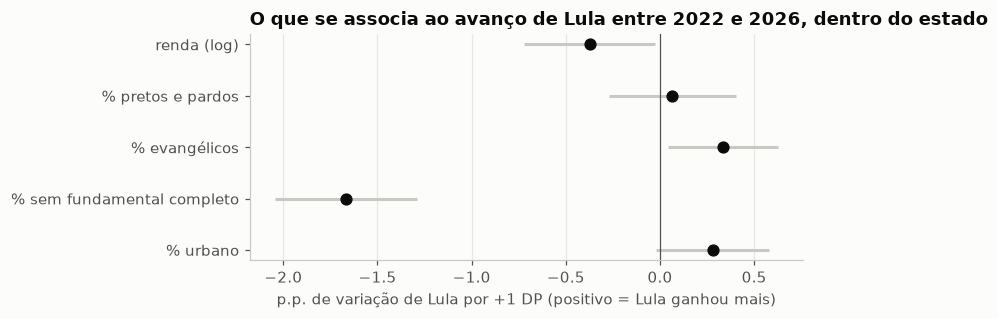

In [8]:
r = res["variação 2022→2026"]
ci = r.conf_int().loc[z]
fig, ax = plt.subplots(figsize=(7.5, 3))
yy = np.arange(len(z))[::-1]
ax.errorbar(r.params[z], yy, xerr=[r.params[z] - ci[0], ci[1] - r.params[z]], fmt="o", color=TINTA,
            ecolor="#c9c8c2", elinewidth=2, capsize=0, ms=7)
ax.set_yticks(yy, [VARS[s[2:]] for s in z]); ax.axvline(0, color="#52514e", lw=0.8); ax.grid(axis="y", visible=False)
ax.set_xlabel("p.p. de variação de Lula por +1 DP (positivo = Lula ganhou mais)")
ax.set_title("O que se associa ao avanço de Lula entre 2022 e 2026, dentro do estado")
plt.tight_layout(); plt.show()

**Leitura.** Dentro do estado, o retrato de 2022 e o de 2026 são quase iguais: % de pretos e pardos é a variável mais associada ao voto em Lula (≈ +10,6 p.p. por desvio-padrão), evangélicos e urbanização puxam para o outro lado, e renda, depois desses controles, pesa pouco.

A **variação** de 2022 para 2026 tem outro dono: **instrução**. Comparando municípios do mesmo estado, Lula perdeu mais onde há mais adultos sem fundamental completo (−1,7 p.p. por desvio-padrão). Com instrução no modelo, renda sai com sinal levemente negativo, e % de evangélicos levemente positivo: a distância de Lula entre os evangélicos já estava dada em 2022 e não aumentou. Renda e instrução andam muito juntas no Brasil, então a separação entre as duas é frágil; o que é robusto é que o recuo de Lula está nos municípios de menor escolaridade.

## 7. Entre os municípios mais pobres, onde está o voto em Flávio?

Restrinjo à metade mais pobre dos municípios (renda abaixo da mediana municipal) e olho Flávio no segundo turno de 2026.

In [9]:
p = w[w.renda < w.renda.median()].copy()
p["flavio_pct"] = 100 - p.lula_pct_2026
print(f"{len(p):,} municípios, {p.validos_2026.sum() / 1e6:.1f} milhões de votos válidos; "
      f"Flávio {100 * p.dir_2026.sum() / (p.lula_2026 + p.dir_2026).sum():.1f}% no confronto direto")
por_reg = p.groupby("regiao").apply(lambda x: pd.Series({
    "municípios": len(x), "Flávio venceu": (x.flavio_pct > 50).sum(),
    "Flávio %": 100 * x.dir_2026.sum() / (x.lula_2026 + x.dir_2026).sum(),
    "votos de Flávio (mi)": x.dir_2026.sum() / 1e6})).loc[REG]
display(por_reg)

rr = fit("I(100 - lula_pct_2026)", d=p)
print("Flávio 2026 na metade mais pobre, p.p. por +1 DP, dentro da UF:")
print((rr.params[z].rename(lambda s: VARS[s[2:]])).round(1).to_string())

fora = p[(p.regiao != "Nordeste") & (p["pop"] > 20_000)].sort_values("flavio_pct", ascending=False)
cols = ["municipio", "uf", "renda", "pct_evang", "pct_preta_parda", "pct_urbano", "flavio_pct"]
print("\nMunicípios pobres fora do Nordeste com mais de 20 mil habitantes, mais votados em Flávio:")
display(fora[cols].head(12).set_index("municipio"))

2,785 municípios, 36.6 milhões de votos válidos; Flávio 33.3% no confronto direto


,municípios,Flávio venceu,Flávio %,votos de Flávio (mi)
regiao,,,,
Norte,370.0,116.0,42.8,2.2
Nordeste,"1,751.0",13.0,27.3,6.8
Centro-Oeste,74.0,41.0,49.9,0.3
Sudeste,544.0,150.0,47.9,2.8
Sul,46.0,27.0,52.2,0.1


Flávio 2026 na metade mais pobre, p.p. por +1 DP, dentro da UF:
renda (log)                   9.9
% pretos e pardos            -3.8
% evangélicos                 4.8
% sem fundamental completo    3.4
% urbano                      1.3

Municípios pobres fora do Nordeste com mais de 20 mil habitantes, mais votados em Flávio:


,uf,renda,pct_evang,pct_preta_parda,pct_urbano,flavio_pct
municipio,,,,,,
URUARÁ,PA,"1,111.2",39.2,77.9,59.0,78.3
RORAINÓPOLIS,RR,"1,141.6",38.8,79.0,74.4,73.2
MEDICILÂNDIA,PA,"1,010.4",43.3,79.5,39.7,72.9
APUÍ,AM,"1,346.5",38.0,72.1,53.0,72.7
MACHADINHO D'OESTE,RO,"1,350.3",47.4,73.1,54.2,72.6
SÃO FÉLIX DO XINGU,PA,"1,285.4",38.3,77.8,59.8,72.4
SENA MADUREIRA,AC,"1,070.9",36.9,80.4,65.2,72.3
CARACARAÍ,RR,"1,003.7",39.1,77.7,53.0,71.9
ALTO ALEGRE,RR,749.8,20.7,34.0,22.6,71.7


**Leitura.** Na metade mais pobre dos municípios, Flávio teve 33% no confronto direto, e 6,8 dos seus 12,2 milhões de votos ali vieram do Nordeste. Fora do Nordeste o quadro muda: Flávio venceu em cerca de um terço dos municípios pobres do Norte (116 de 370) e do Sudeste (150 de 544), e passou de 50% no Sul e no Centro-Oeste.

Dentro do estado, entre os pobres, Flávio é mais forte nos **menos pobres** (+9,9 p.p. por desvio-padrão de renda), nos mais evangélicos e nos com menos pretos e pardos. Os campeões fora do Nordeste são, como no primeiro turno, municípios de fronteira agrícola e extrativista do Norte (PA, RR, AM, RO, AC), com mais de 70% para Flávio.

## 8. O que este notebook não responde

| Pergunta | O que os dados municipais dizem | O que falta |
|---|---|---|
| O eleitor pobre mudou de voto? | Só que municípios pobres mudaram (ou não) | Pesquisa individual (Datafolha, Quaest, ESEB) |
| Programas sociais pesaram? | Nada: não há variável de transferência aqui | Cruzar com cobertura municipal do Bolsa Família (MDS) |
| Renda mudou desde 2022? | Usa a renda do Censo 2022 para 2026 também | Renda municipal mais recente (PNAD não desce a município) |

A unidade é o município: tudo aqui é sobre lugares, não pessoas.

## 9. Conclusões

1. **O quintil mais pobre continua sendo o mais lulista** (71% no segundo turno de 2026) e concentra 29% dos votos de Lula.
2. **Mas Lula venceu 2026 sem crescer nele.** Do segundo turno de 2022 para o de 2026, Lula caiu 1,4 p.p. nos municípios mais pobres e subiu em todos os outros quintis, até +2,3 no mais rico. 62% do ganho de margem veio dos quintis 4 e 5.
3. **Não é efeito regional:** o recuo no quintil mais pobre aparece dentro do Norte, do Nordeste e do Sudeste.
4. **O que separa o recuo é instrução**: dentro do estado, Lula perdeu mais onde há mais adultos sem fundamental completo. Cor/raça segue como a variável mais associada ao nível do voto, e não mudou.
5. **O "pobre de direita" do segundo turno mora fora do Nordeste**: na fronteira agrícola do Norte e nos municípios pobres do Sul, Centro-Oeste e Sudeste, nos menos pobres entre os pobres e nos mais evangélicos.

**Limites.** Município não é eleitor; a renda e o perfil são do Censo 2022 e valem para as duas eleições.